### References

*   **GEKKO Optimization Suite Article:**
    Beal, L. D. R., Hill, D., Martin, R. A., & Hedengren, J. D. (2018). *GEKKO Optimization Suite*. Processes, 6(8), 106. doi.org

*   **APMonitor Course Website (ME575):**
    Hedengren, J. D. (n.d.). *Design Optimization (ME 575)*. APMonitor. Retrieved January 9, 2026, from https://apmonitor.com/me575/index.php/Main/HomePage

*   **Mr. P Solver (YouTube Channel):**
    Mr. P Solver. (n.d.). *Home* [YouTube channel]. YouTube. Retrieved January 9, 2026, from https://www.youtube.com/@MrPSolver

*   **The OR Book (Textbook):**
    Winston, W. L. (2004). *Operations Research: Applications and Algorithms* (4th ed.). Thomson Brooks/Cole.


OR book pg86,pg179
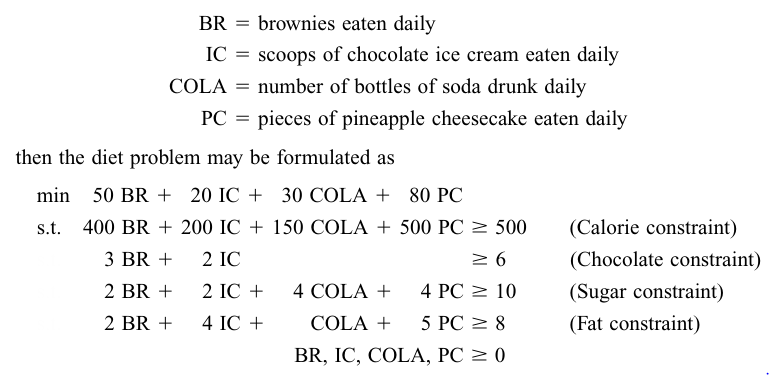

In [21]:
from gekko import GEKKO

# Simple version
m = GEKKO(remote=False)

# Variables
BR = m.Var(lb=0, name='BR')
IC = m.Var(lb=0, name='IC')
COLA = m.Var(lb=0, name='COLA')
PC = m.Var(lb=0, name='PC')

# Objective: Minimize cost
m.Minimize(50*BR + 20*IC + 30*COLA + 80*PC)

# Constraints
m.Equation(400*BR + 200*IC + 150*COLA + 500*PC >= 500)  # Calories
m.Equation(3*BR + 2*IC >= 6)                           # Chocolate
m.Equation(2*BR + 2*IC + 4*COLA + 4*PC >= 10)          # Sugar
m.Equation(2*BR + 4*IC + COLA + 5*PC >= 8)             # Fat

# Solve
m.options.SOLVER = 1
#m.solve()
m.solve()

# Results
print("Optimal Diet:")
print(f"Brownies (BR): {BR.value[0]:.4f}")
print(f"Ice Cream (IC): {IC.value[0]:.4f} scoops")
print(f"Soda (COLA): {COLA.value[0]:.4f} bottles")
print(f"Cheesecake (PC): {PC.value[0]:.4f} pieces")
print(f"\nMinimum Daily Cost: ${m.options.OBJFCNVAL:.2f}")

 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :  0
   Constants    :  0
   Variables    :  8
   Intermediates:  0
   Connections  :  0
   Equations    :  5
   Residuals    :  5
 
 Number of state variables:    8
 Number of total equations: -  4
 Number of slack variables: -  4
 ---------------------------------------
 Degrees of freedom       :    0
 
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0  9.00000E+01  2.50000E+00
    2  9.00000E+01  0.00000E+00
 Successful solution
 
 ---------------------------------------------------
 Solver         :  APOPT (v1.0)
 Solution time  :  0.024499999999999994 sec
 Objective      :  90.
 Succe

DIET OPTIMIZATION PROBLEM

Decision Variables:
----------------------------------------
BR  = Brownies eaten daily
IC  = Scoops of chocolate ice cream eaten daily
COLA = Bottles of soda drunk daily
PC  = Pieces of pineapple cheesecake eaten daily

Objective Function:
----------------------------------------
Minimize: 50*BR + 20*IC + 30*COLA + 80*PC

Constraints:
----------------------------------------
1. 400*BR + 200*IC + 150*COLA + 500*PC ≥ 500 (Calories)
2. 3*BR + 2*IC ≥ 6 (Chocolate)
3. 2*BR + 2*IC + 4*COLA + 4*PC ≥ 10 (Sugar)
4. 2*BR + 4*IC + COLA + 5*PC ≥ 8 (Fat)
5. BR, IC, COLA, PC ≥ 0

SOLVING...
 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :  0
   Constants    :  0
   Variables    :  8
   Intermediates:  0
   Connections  :  0
   Equations    :  5
   Res


Would you like to see sensitivity analysis? (y/n):  y



SENSITIVITY ANALYSIS

1. Effect of changing calorie requirement:
----------------------------------------
 Calories Required  Cost   BR   IC  COLA   PC
               400 90.00 0.00 3.00  1.00 0.00
               450 90.00 0.00 3.00  1.00 0.00
               500 90.00 0.00 3.00  1.00 0.00
               550 90.00 0.00 3.00  1.00 0.00
               600 90.00 0.00 3.00  1.00 0.00

💡 Insight: As calorie requirement increases, the minimum cost increases.



Would you like to see visualization? (y/n):  y


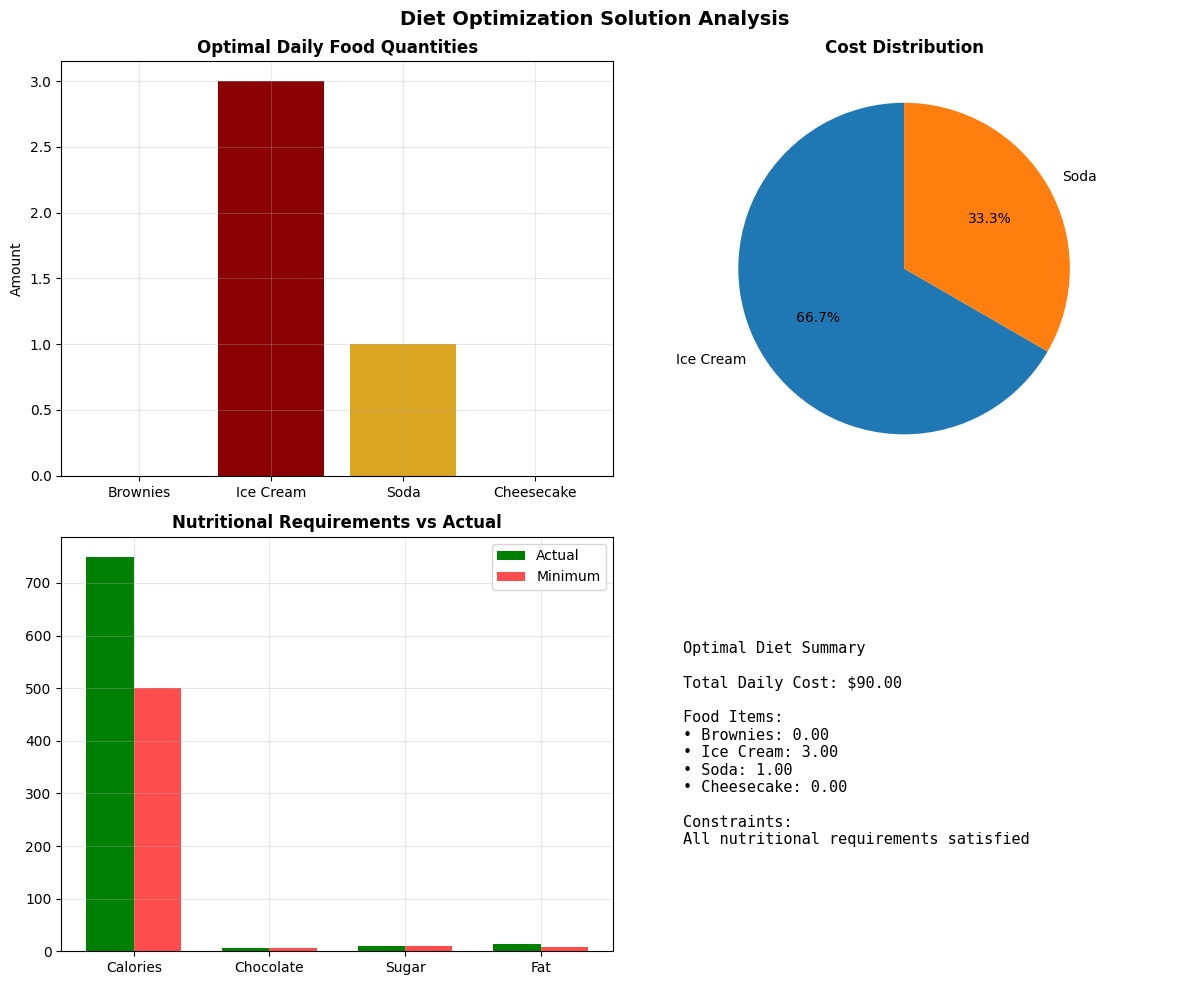


PROGRAM COMPLETE


In [7]:
from gekko import GEKKO
import numpy as np
import pandas as pd

# ============================================================================
# DIET OPTIMIZATION PROBLEM SOLUTION
# ============================================================================

def solve_diet_problem():
    """
    Solve the diet optimization problem:
    Minimize cost while meeting nutritional requirements
    """
    
    # Initialize GEKKO model
    m = GEKKO(remote=False)
    m.options.SOLVER = 1  # APOPT solver
    m.options.IMODE = 3   # Steady state optimization
    
    # ============================================================================
    # DECISION VARIABLES
    # ============================================================================
    print("=" * 70)
    print("DIET OPTIMIZATION PROBLEM")
    print("=" * 70)
    print("\nDecision Variables:")
    print("-" * 40)
    
    # Define variables with meaningful names
    BR = m.Var(lb=0, name='BR')      # Brownies eaten daily
    IC = m.Var(lb=0, name='IC')      # Scoops of chocolate ice cream
    COLA = m.Var(lb=0, name='COLA')  # Bottles of soda
    PC = m.Var(lb=0, name='PC')      # Pineapple cheesecake pieces
    
    print("BR  = Brownies eaten daily")
    print("IC  = Scoops of chocolate ice cream eaten daily")
    print("COLA = Bottles of soda drunk daily")
    print("PC  = Pieces of pineapple cheesecake eaten daily")
    
    # ============================================================================
    # OBJECTIVE FUNCTION: Minimize Total Cost
    # ============================================================================
    print("\nObjective Function:")
    print("-" * 40)
    print("Minimize: 50*BR + 20*IC + 30*COLA + 80*PC")
    
    m.Minimize(50*BR + 20*IC + 30*COLA + 80*PC)
    
    # ============================================================================
    # CONSTRAINTS
    # ============================================================================
    print("\nConstraints:")
    print("-" * 40)
    
    # 1. Calorie constraint: ≥ 500 calories
    m.Equation(400*BR + 200*IC + 150*COLA + 500*PC >= 500)
    print("1. 400*BR + 200*IC + 150*COLA + 500*PC ≥ 500 (Calories)")
    
    # 2. Chocolate constraint: ≥ 6 units
    m.Equation(3*BR + 2*IC >= 6)
    print("2. 3*BR + 2*IC ≥ 6 (Chocolate)")
    
    # 3. Sugar constraint: ≥ 10 units
    m.Equation(2*BR + 2*IC + 4*COLA + 4*PC >= 10)
    print("3. 2*BR + 2*IC + 4*COLA + 4*PC ≥ 10 (Sugar)")
    
    # 4. Fat constraint: ≥ 8 units
    m.Equation(2*BR + 4*IC + COLA + 5*PC >= 8)
    print("4. 2*BR + 4*IC + COLA + 5*PC ≥ 8 (Fat)")
    
    # 5. Non-negativity constraints (already in lb=0)
    print("5. BR, IC, COLA, PC ≥ 0")
    
    # ============================================================================
    # SOLVE THE OPTIMIZATION PROBLEM
    # ============================================================================
    print("\n" + "=" * 70)
    print("SOLVING...")
    print("=" * 70)
    
    try:
        m.solve(disp=True)
        
        if m.options.SOLVESTATUS == 1:
            print("\n✅ OPTIMAL SOLUTION FOUND")
            
            # ============================================================================
            # DISPLAY RESULTS
            # ============================================================================
            print("\n" + "=" * 70)
            print("OPTIMAL DIET PLAN")
            print("=" * 70)
            
            # Get optimal values
            br_opt = BR.value[0]
            ic_opt = IC.value[0]
            cola_opt = COLA.value[0]
            pc_opt = PC.value[0]
            total_cost = m.options.OBJFCNVAL
            
            # Create results table
            results_data = {
                'Food Item': ['Brownies', 'Chocolate Ice Cream', 'Soda', 'Pineapple Cheesecake', 'TOTAL'],
                'Variable': ['BR', 'IC', 'COLA', 'PC', ''],
                'Daily Amount': [br_opt, ic_opt, cola_opt, pc_opt, ''],
                'Unit Cost ($)': [50, 20, 30, 80, ''],
                'Total Cost ($)': [50*br_opt, 20*ic_opt, 30*cola_opt, 80*pc_opt, total_cost]
            }
            
            df_results = pd.DataFrame(results_data)
            print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
            
            # ============================================================================
            # NUTRITIONAL ANALYSIS
            # ============================================================================
            print("\n" + "=" * 70)
            print("NUTRITIONAL ANALYSIS")
            print("=" * 70)
            
            # Calculate nutritional values from optimal solution
            calories = 400*br_opt + 200*ic_opt + 150*cola_opt + 500*pc_opt
            chocolate = 3*br_opt + 2*ic_opt
            sugar = 2*br_opt + 2*ic_opt + 4*cola_opt + 4*pc_opt
            fat = 2*br_opt + 4*ic_opt + cola_opt + 5*pc_opt
            
            nutrition_data = {
                'Nutrient': ['Calories', 'Chocolate', 'Sugar', 'Fat'],
                'Minimum Required': [500, 6, 10, 8],
                'Actual Intake': [calories, chocolate, sugar, fat],
                'Difference': [calories-500, chocolate-6, sugar-10, fat-8],
                'Status': []
            }
            
            # Determine if constraint is met
            for i in range(len(nutrition_data['Nutrient'])):
                if nutrition_data['Difference'][i] >= -1e-6:  # Small tolerance for numerical errors
                    nutrition_data['Status'].append('✓ SATISFIED')
                else:
                    nutrition_data['Status'].append('✗ VIOLATED')
            
            df_nutrition = pd.DataFrame(nutrition_data)
            print(df_nutrition.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
            
            # ============================================================================
            # SENSITIVITY ANALYSIS (Shadow Prices/Dual Values)
            # ============================================================================
            print("\n" + "=" * 70)
            print("ECONOMIC INTERPRETATION")
            print("=" * 70)
            
            # Binding constraints (where slack is approximately 0)
            print("\nBinding Constraints (fully utilized):")
            
            # Calculate slack for each constraint
            slacks = [
                calories - 500,
                chocolate - 6,
                sugar - 10,
                fat - 8
            ]
            
            constraint_names = ['Calories', 'Chocolate', 'Sugar', 'Fat']
            for i, slack in enumerate(slacks):
                if abs(slack) < 1e-6:
                    print(f"  ✓ {constraint_names[i]} constraint is binding")
                else:
                    print(f"  • {constraint_names[i]} constraint has {slack:.2f} units of surplus")
            
            # Interpretation
            print(f"\n💡 Interpretation:")
            print(f"• The minimum daily cost is ${total_cost:.2f}")
            print(f"• This diet provides exactly or more than the minimum nutritional requirements")
            
            # Check for zero consumption items
            zero_items = []
            if br_opt < 1e-6:
                zero_items.append("Brownies")
            if ic_opt < 1e-6:
                zero_items.append("Chocolate Ice Cream")
            if cola_opt < 1e-6:
                zero_items.append("Soda")
            if pc_opt < 1e-6:
                zero_items.append("Pineapple Cheesecake")
            
            if zero_items:
                print(f"• Items not consumed: {', '.join(zero_items)}")
            
            # ============================================================================
            # ALTERNATIVE FORMULATION USING MATRICES (for comparison)
            # ============================================================================
            print("\n" + "=" * 70)
            print("MATRIX FORMULATION (For Reference)")
            print("=" * 70)
            
            # Show the problem in matrix form
            print("\nMinimize: CᵀX")
            print("Where C = [50, 20, 30, 80]")
            print("      X = [BR, IC, COLA, PC]ᵀ")
            
            print("\nSubject to: AX ≥ b")
            print("Where A = [[400, 200, 150, 500],")
            print("           [  3,   2,   0,   0],")
            print("           [  2,   2,   4,   4],")
            print("           [  2,   4,   1,   5]]")
            print("      b = [500, 6, 10, 8]ᵀ")
            
        else:
            print(f"\n❌ Solver failed with status: {m.options.SOLVESTATUS}")
            
    except Exception as e:
        print(f"\n❌ Error during solving: {e}")

# ============================================================================
# ADDITIONAL ANALYSIS FUNCTIONS
# ============================================================================

def analyze_diet_sensitivity():
    """
    Perform sensitivity analysis on the diet problem
    """
    print("\n" + "=" * 70)
    print("SENSITIVITY ANALYSIS")
    print("=" * 70)
    
    # We'll solve the problem multiple times with parameter variations
    print("\n1. Effect of changing calorie requirement:")
    print("-" * 40)
    
    calorie_levels = [400, 450, 500, 550, 600]
    results = []
    
    for calories in calorie_levels:
        m = GEKKO(remote=False)
        BR = m.Var(lb=0)
        IC = m.Var(lb=0)
        COLA = m.Var(lb=0)
        PC = m.Var(lb=0)
        
        m.Minimize(50*BR + 20*IC + 30*COLA + 80*PC)
        m.Equation(400*BR + 200*IC + 150*COLA + 500*PC >= calories)
        m.Equation(3*BR + 2*IC >= 6)
        m.Equation(2*BR + 2*IC + 4*COLA + 4*PC >= 10)
        m.Equation(2*BR + 4*IC + COLA + 5*PC >= 8)
        
        m.options.SOLVER = 1
        m.options.IMODE = 3
        m.solve(disp=False)
        
        if m.options.SOLVESTATUS == 1:
            results.append({
                'Calories Required': calories,
                'Cost': m.options.OBJFCNVAL,
                'BR': BR.value[0],
                'IC': IC.value[0],
                'COLA': COLA.value[0],
                'PC': PC.value[0]
            })
    
    # Display sensitivity results
    df_sensitivity = pd.DataFrame(results)
    print(df_sensitivity.to_string(index=False, float_format=lambda x: f"{x:.2f}" if isinstance(x, float) else str(x)))
    
    print("\n💡 Insight: As calorie requirement increases, the minimum cost increases.")
    
def visualize_diet_solution():
    """
    Visualize the diet solution (if matplotlib is available)
    """
    try:
        import matplotlib.pyplot as plt
        
        # Get the optimal solution
        m = GEKKO(remote=False)
        BR = m.Var(lb=0)
        IC = m.Var(lb=0)
        COLA = m.Var(lb=0)
        PC = m.Var(lb=0)
        
        m.Minimize(50*BR + 20*IC + 30*COLA + 80*PC)
        m.Equation(400*BR + 200*IC + 150*COLA + 500*PC >= 500)
        m.Equation(3*BR + 2*IC >= 6)
        m.Equation(2*BR + 2*IC + 4*COLA + 4*PC >= 10)
        m.Equation(2*BR + 4*IC + COLA + 5*PC >= 8)
        
        m.options.SOLVER = 1
        m.options.IMODE = 3
        m.solve(disp=False)
        
        if m.options.SOLVESTATUS == 1:
            # Prepare data for visualization
            items = ['Brownies', 'Ice Cream', 'Soda', 'Cheesecake']
            amounts = [BR.value[0], IC.value[0], COLA.value[0], PC.value[0]]
            costs = [50*BR.value[0], 20*IC.value[0], 30*COLA.value[0], 80*PC.value[0]]
            
            # Create subplots
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))
            
            # 1. Bar chart of food amounts
            axes[0, 0].bar(items, amounts, color=['#8B4513', '#8B0000', '#DAA520', '#FFD700'])
            axes[0, 0].set_title('Optimal Daily Food Quantities', fontsize=12, fontweight='bold')
            axes[0, 0].set_ylabel('Amount')
            axes[0, 0].grid(True, alpha=0.3)
            
            # 2. Pie chart of cost distribution
            axes[0, 1].pie([c for c in costs if c > 0], 
                          labels=[items[i] for i in range(4) if costs[i] > 0],
                          autopct='%1.1f%%', startangle=90)
            axes[0, 1].set_title('Cost Distribution', fontsize=12, fontweight='bold')
            
            # 3. Bar chart of nutritional contribution
            nutrition_labels = ['Calories', 'Chocolate', 'Sugar', 'Fat']
            nutrition_contribution = [
                400*BR.value[0] + 200*IC.value[0] + 150*COLA.value[0] + 500*PC.value[0],
                3*BR.value[0] + 2*IC.value[0],
                2*BR.value[0] + 2*IC.value[0] + 4*COLA.value[0] + 4*PC.value[0],
                2*BR.value[0] + 4*IC.value[0] + COLA.value[0] + 5*PC.value[0]
            ]
            nutrition_minimum = [500, 6, 10, 8]
            
            x = np.arange(len(nutrition_labels))
            width = 0.35
            axes[1, 0].bar(x - width/2, nutrition_contribution, width, label='Actual', color='green')
            axes[1, 0].bar(x + width/2, nutrition_minimum, width, label='Minimum', color='red', alpha=0.7)
            axes[1, 0].set_title('Nutritional Requirements vs Actual', fontsize=12, fontweight='bold')
            axes[1, 0].set_xticks(x)
            axes[1, 0].set_xticklabels(nutrition_labels)
            axes[1, 0].legend()
            axes[1, 0].grid(True, alpha=0.3)
            
            # 4. Text summary
            axes[1, 1].axis('off')
            summary_text = (
                f"Optimal Diet Summary\n\n"
                f"Total Daily Cost: ${m.options.OBJFCNVAL:.2f}\n\n"
                f"Food Items:\n"
                f"• Brownies: {BR.value[0]:.2f}\n"
                f"• Ice Cream: {IC.value[0]:.2f}\n"
                f"• Soda: {COLA.value[0]:.2f}\n"
                f"• Cheesecake: {PC.value[0]:.2f}\n\n"
                f"Constraints:\n"
                f"All nutritional requirements satisfied"
            )
            axes[1, 1].text(0.1, 0.5, summary_text, fontsize=11, 
                           verticalalignment='center', fontfamily='monospace')
            
            plt.suptitle('Diet Optimization Solution Analysis', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
            
    except ImportError:
        print("\nNote: Install matplotlib for visualization: pip install matplotlib")

# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    # Solve the main diet problem
    solve_diet_problem()
    
    # Ask user if they want additional analysis
    print("\n" + "=" * 70)
    response = input("\nWould you like to see sensitivity analysis? (y/n): ")
    if response.lower() == 'y':
        analyze_diet_sensitivity()
    
    response = input("\nWould you like to see visualization? (y/n): ")
    if response.lower() == 'y':
        visualize_diet_solution()
    
    print("\n" + "=" * 70)
    print("PROGRAM COMPLETE")
    print("=" * 70)

In [7]:
for i in range(5):
    print(i)

0
1
2
3
4


In [9]:
s=0
p=1
i=1
print(i,p,s)
while i<5:
    s=s+i
    p=p*i
    i=i+1
    print(i,p,s)
    

1 1 0
2 1 1
3 2 3
4 6 6
5 24 10


In [23]:
m.cleanup()